<a href="https://colab.research.google.com/github/Sai-Jhansi-hub/customer-sales-analysis/blob/main/Customer_Sales_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [29]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [30]:
import os

folder = '/content/drive/MyDrive/Module-7_Introduction_to_Data_Science/mini_project'

print(os.listdir(folder))

['Mini Project: Customer Sales Analysis.gdoc', 'Sample - Superstore.csv', 'Customer_Sales_Analysis.ipynb']


In [31]:
# Task 2: Load and Understand the Dataset

import pandas as pd
import numpy as np

# 1. Read the CSV file
df = pd.read_csv(
    '/content/drive/MyDrive/Module-7_Introduction_to_Data_Science/mini_project/Sample - Superstore.csv',
    encoding='latin1'
)

# Standardize column names
df.columns = df.columns.str.strip().str.lower().str.replace(' ', '_')

# 2. Check rows and columns
print("Dataset shape:", df.shape)
print("Number of records:", df.shape[0])
print("Number of columns:", df.shape[1])

# 3. Check column names
print("\nColumn names:")
print(df.columns.tolist())

# 4. Check data types
print("\nData types:")
print(df.dtypes)

# 5. Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# 6. Check duplicate records
print("\nDuplicate records:", df.duplicated().sum())

# 7. Generate basic statistics
print("\nBasic statistics:")
display(df.describe(include='all').T)

# 9. Find important dataset metrics
print("\nNumber of customers:", df['customer_id'].nunique())
print("Number of products:", df['product_id'].nunique())
print("Number of categories:", df['category'].nunique())
print("Number of regions:", df['region'].nunique())
print("Number of unique orders:", df['order_id'].nunique())

# 10. Find date range
print("\nOrder date range:")
print("Start date:", df['order_date'].min())
print("End date:", df['order_date'].max())

# 11. Display first five records
print("\nFirst five records:")
display(df.head())


Dataset shape: (9994, 21)
Number of records: 9994
Number of columns: 21

Column names:
['row_id', 'order_id', 'order_date', 'ship_date', 'ship_mode', 'customer_id', 'customer_name', 'segment', 'country', 'city', 'state', 'postal_code', 'region', 'product_id', 'category', 'sub-category', 'product_name', 'sales', 'quantity', 'discount', 'profit']

Data types:
row_id             int64
order_id          object
order_date        object
ship_date         object
ship_mode         object
customer_id       object
customer_name     object
segment           object
country           object
city              object
state             object
postal_code        int64
region            object
product_id        object
category          object
sub-category      object
product_name      object
sales            float64
quantity           int64
discount         float64
profit           float64
dtype: object

Missing values:
row_id           0
order_id         0
order_date       0
ship_date        0
ship_mod

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
row_id,9994.0,NaN,NaN,NaN,4997.5,2885.163629,1.0,2499.25,4997.5,7495.75,9994.0
order_id,9994,5009,CA-2017-100111,14,NaN,NaN,NaN,NaN,NaN,NaN,NaN
order_date,9994,1237,9/5/2016,38,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ship_date,9994,1334,12/16/2015,35,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ship_mode,9994,4,Standard Class,5968,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_id,9994,793,WB-21850,37,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_name,9994,793,William Brown,37,NaN,NaN,NaN,NaN,NaN,NaN,NaN
segment,9994,3,Consumer,5191,NaN,NaN,NaN,NaN,NaN,NaN,NaN
country,9994,1,United States,9994,NaN,NaN,NaN,NaN,NaN,NaN,NaN
city,9994,531,New York City,915,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Number of customers: 793
Number of products: 1862
Number of categories: 3
Number of regions: 4
Number of unique orders: 5009

Order date range:
Start date: 1/1/2017
End date: 9/9/2017

First five records:


,row_id,order_id,order_date,ship_date,ship_mode,customer_id,customer_name,segment,country,city,...,postal_code,region,product_id,category,sub-category,product_name,sales,quantity,discount,profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [39]:
#Task 3: Data Cleaning

# 1. Standardize column names
df.columns = df.columns.str.strip().str.lower().str.replace(' ', '_')

# 2. Remove duplicates
df.drop_duplicates(inplace=True)

# 3. Convert dates
df['order_date'] = pd.to_datetime(df['order_date'], errors='coerce')
df['ship_date'] = pd.to_datetime(df['ship_date'], errors='coerce')
# 7. Create date columns
df['year'] = df['order_date'].dt.year
df['month'] = df['order_date'].dt.month

# 4. Convert numerical columns
for col in ['sales', 'quantity', 'profit', 'discount']:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# 5. Remove rows missing important values
df.dropna(subset=['order_id', 'order_date', 'customer_id',
                  'product_id', 'sales', 'quantity'], inplace=True)

# 6. Remove invalid sales and quantities
df = df[(df['sales'] >= 0) & (df['quantity'] > 0)].copy()

# 8. Check cleaned data
print("Final shape:", df.shape)
print("Duplicates:", df.duplicated().sum())
print("Missing values:", df.isnull().sum().sum())

# Save the cleaned dataset
output_path = '/content/drive/MyDrive/Module-7_Introduction_to_Data_Science/mini_project/outputs/datasets/cleaned_customer_sales_analysis.csv'

df.to_csv(output_path, index=False)

print("Cleaned dataset saved successfully!")

display(df.head())


Final shape: (9994, 23)
Duplicates: 0
Missing values: 0
Cleaned dataset saved successfully!


,row_id,order_id,order_date,ship_date,ship_mode,customer_id,customer_name,segment,country,city,...,product_id,category,sub-category,product_name,sales,quantity,discount,profit,year,month
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136,2016,11
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820,2016,11
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714,2016,6
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310,2015,10
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164,2015,10


In [40]:
# Task 4: Customer Analysis

# 1. Calculate customer performance
customer_analysis = df.groupby(['customer_id', 'customer_name']).agg(
    total_sales=('sales', 'sum'),
    total_profit=('profit', 'sum'),
    total_orders=('order_id', 'nunique')
).reset_index()
#display(customer_analysis)

# 2. Calculate Average Order Value (AOV)
customer_analysis['aov'] = (customer_analysis['total_sales'] / customer_analysis['total_orders'])

print("Top 10 Customers by Sales")
display(customer_analysis.sort_values('total_sales', ascending=False).head(10))

print("Top 10 Customers by Profit")
display(customer_analysis.sort_values('total_profit', ascending=False).head(10))

print("Top 10 Customers by Number of Orders")
display(customer_analysis.sort_values('total_orders', ascending=False)[['customer_name', 'total_orders']].head(10))

Top 10 Customers by Sales


,customer_id,customer_name,total_sales,total_profit,total_orders,aov
700,SM-20320,Sean Miller,25043.050,-1980.7393,5,5008.610000
741,TC-20980,Tamara Chand,19052.218,8981.3239,5,3810.443600
621,RB-19360,Raymond Buch,15117.339,6976.0959,6,2519.556500
730,TA-21385,Tom Ashbrook,14595.620,4703.7883,4,3648.905000
6,AB-10105,Adrian Barton,14473.571,5444.8055,10,1447.357100
434,KL-16645,Ken Lonsdale,14175.229,806.8550,12,1181.269083
669,SC-20095,Sanjit Chand,14142.334,5757.4119,9,1571.370444
327,HL-15040,Hunter Lopez,12873.298,5622.4292,6,2145.549667
683,SE-20110,Sanjit Engle,12209.438,2650.6769,11,1109.948909
131,CC-12370,Christopher Conant,12129.072,2177.0493,5,2425.814400


Top 10 Customers by Profit


,customer_id,customer_name,total_sales,total_profit,total_orders,aov
741,TC-20980,Tamara Chand,19052.218,8981.3239,5,3810.443600
621,RB-19360,Raymond Buch,15117.339,6976.0959,6,2519.556500
669,SC-20095,Sanjit Chand,14142.334,5757.4119,9,1571.370444
327,HL-15040,Hunter Lopez,12873.298,5622.4292,6,2145.549667
6,AB-10105,Adrian Barton,14473.571,5444.8055,10,1447.357100
730,TA-21385,Tom Ashbrook,14595.620,4703.7883,4,3648.905000
160,CM-12385,Christopher Martinez,8954.020,3899.8904,4,2238.505000
424,KD-16495,Keith Dawkins,8181.256,3038.6254,12,681.771333
48,AR-10540,Andy Reiter,6608.448,2884.6208,6,1101.408000
234,DR-12940,Daniel Raglin,8350.868,2869.0760,8,1043.858500


Top 10 Customers by Number of Orders


,customer_name,total_orders
275,Emily Phan,17
691,Sally Hughsby,13
576,Noel Staavos,13
591,Patrick Gardner,13
791,Zuschuss Carroll,13
245,Erin Ashbrook,13
356,Joel Eaton,13
147,Chloris Kastensmidt,13
34,Anna Häberlin,12
623,Rick Bensley,12


In [41]:
# Task 5: Product & Category Analysis

# 1. Top 10 products by sales
print("Top 10 Products by Sales")
display(df.groupby('product_name')['sales'].sum().sort_values(ascending=False).head(10))

# 2. Top 10 products by profit
print("Top 10 Products by Profit")
display(df.groupby('product_name')['profit'].sum().sort_values(ascending=False).head(10))

# 3. Sales by category
print("Sales by Category")
display(df.groupby('category')['sales'].sum().sort_values(ascending=False))

# 4. Profit by category
print("Profit by Category")
display(df.groupby('category')['profit'].sum().sort_values(ascending=False))

# 5. Sales by sub-category
print("Sales by Sub-Category")
display(df.groupby('sub-category')['sales'].sum().sort_values(ascending=False))

# 6. Find products with high sales but low profit
product_analysis = df.groupby('product_name').agg(
    total_sales=('sales', 'sum'),
    total_profit=('profit', 'sum')
).reset_index()

print("High-Sales Products with Low Profit")
display(product_analysis.sort_values('total_sales', ascending=False).head(10).sort_values('total_profit'))


Top 10 Products by Sales


,sales
product_name,
Canon imageCLASS 2200 Advanced Copier,61599.824
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind,27453.384
Cisco TelePresence System EX90 Videoconferencing Unit,22638.480
HON 5400 Series Task Chairs for Big and Tall,21870.576
GBC DocuBind TL300 Electric Binding System,19823.479
GBC Ibimaster 500 Manual ProClick Binding System,19024.500
Hewlett Packard LaserJet 3310 Copier,18839.686
"HP Designjet T520 Inkjet Large Format Printer - 24"" Color",18374.895
GBC DocuBind P400 Electric Binding System,17965.068


Top 10 Products by Profit


,profit
product_name,
Canon imageCLASS 2200 Advanced Copier,25199.9280
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind,7753.0390
Hewlett Packard LaserJet 3310 Copier,6983.8836
Canon PC1060 Personal Laser Copier,4570.9347
"HP Designjet T520 Inkjet Large Format Printer - 24"" Color",4094.9766
Ativa V4110MDD Micro-Cut Shredder,3772.9461
"3D Systems Cube Printer, 2nd Generation, Magenta",3717.9714
Plantronics Savi W720 Multi-Device Wireless Headset System,3696.2820
Ibico EPK-21 Electric Binding System,3345.2823


Sales by Category


...

,profit
category,
Technology,145454.9481
Office Supplies,122490.8008
Furniture,18451.2728


Sales by Sub-Category


,sales
sub-category,
Phones,330007.0540
Chairs,328449.1030
Storage,223843.6080
Tables,206965.5320
Binders,203412.7330
Machines,189238.6310
Accessories,167380.3180
Copiers,149528.0300
Bookcases,114879.9963


High-Sales Products with Low Profit


,product_name,total_sales,total_profit
683,GBC DocuBind P400 Electric Binding System,17965.068,-1.878166e+03
444,Cisco TelePresence System EX90 Videoconferenci...,22638.480,-1.811078e+03
813,High Speed Automatic Electric Letter Opener,17030.312,-2.620048e+02
786,HON 5400 Series Task Chairs for Big and Tall,21870.576,5.684342e-14
688,GBC Ibimaster 500 Manual ProClick Binding System,19024.500,7.609800e+02
686,GBC DocuBind TL300 Electric Binding System,19823.479,2.233505e+03
787,HP Designjet T520 Inkjet Large Format Printer ...,18374.895,4.094977e+03
805,Hewlett Packard LaserJet 3310 Copier,18839.686,6.983884e+03
650,Fellowes PB500 Electric Punch Plastic Comb Bin...,27453.384,7.753039e+03
404,Canon imageCLASS 2200 Advanced Copier,61599.824,2.519993e+04


In [43]:
# Task 6: Regional & Time Analysis

# 1. Load the cleaned dataset
file_path = '/content/drive/MyDrive/Module-7_Introduction_to_Data_Science/mini_project/outputs/datasets/cleaned_customer_sales_analysis.csv'
df = pd.read_csv(file_path)

# 2. Convert dates and create date columns
df['order_date'] = pd.to_datetime(df['order_date'], errors='coerce')
df['year'] = df['order_date'].dt.year
df['month'] = df['order_date'].dt.month
df['year_month'] = df['order_date'].dt.to_period('M').astype(str)

# 3. Sales and profit by region
region_analysis = df.groupby('region').agg(
    total_sales=('sales', 'sum'),
    total_profit=('profit', 'sum')
).reset_index()

print("Sales and Profit by Region")
display(region_analysis.sort_values('total_sales', ascending=False))

# 4. Sales by state
state_sales = df.groupby('state').agg(
    total_sales=('sales', 'sum')
).reset_index()

print("Top 10 States by Sales")
display(state_sales.sort_values('total_sales', ascending=False).head(10))

# 5. Monthly sales and profit
monthly_analysis = df.groupby('year_month').agg(
    total_sales=('sales', 'sum'),
    total_profit=('profit', 'sum')
).reset_index()

print("Monthly Sales and Profit")
display(monthly_analysis)

# 6. Yearly sales
yearly_sales = df.groupby('year').agg(
    total_sales=('sales', 'sum')
).reset_index()

print("Yearly Sales")
display(yearly_sales)

# 7. Find highest and lowest performing regions
print("Highest Sales Region:")
display(region_analysis.loc[region_analysis['total_sales'].idxmax()])

print("Lowest Profit Region:")
display(region_analysis.loc[region_analysis['total_profit'].idxmin()])

# 8. Find highest and lowest sales months
print("Highest Sales Month:")
display(monthly_analysis.loc[monthly_analysis['total_sales'].idxmax()])

print("Lowest Sales Month:")
display(monthly_analysis.loc[monthly_analysis['total_sales'].idxmin()])


Sales and Profit by Region


,region,total_sales,total_profit
3,West,725457.8245,108418.4489
1,East,678781.2400,91522.7800
0,Central,501239.8908,39706.3625
2,South,391721.9050,46749.4303


Top 10 States by Sales


,state,total_sales
3,California,457687.6315
30,New York,310876.2710
41,Texas,170188.0458
45,Washington,138641.2700
36,Pennsylvania,116511.9140
8,Florida,89473.7080
11,Illinois,80166.1010
33,Ohio,78258.1360
20,Michigan,76269.6140
44,Virginia,70636.7200


Monthly Sales and Profit


...

,0
region,Central
total_sales,501239.8908
total_profit,39706.3625


Highest Sales Month:


,46
year_month,2017-11
total_sales,118447.825
total_profit,9690.1037


Lowest Sales Month:


,1
year_month,2014-02
total_sales,4519.892
total_profit,862.3084


In [49]:
#Step 1A: Verify the file path
from google.colab import drive
drive.mount('/content/drive')

import os

csv_path = '/content/drive/MyDrive/Module-7_Introduction_to_Data_Science/mini_project/outputs/datasets/cleaned_customer_sales_analysis.csv'

print("File exists:", os.path.exists(csv_path))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
File exists: True


In [50]:
#Step 2: Create the SQL database
import pandas as pd
import sqlite3

# Load cleaned dataset
df = pd.read_csv(csv_path)

# Standardize column names
df.columns = df.columns.str.strip().str.lower().str.replace('-', '_', regex=False)

# Create database and sales table
db_path = '/content/drive/MyDrive/Module-7_Introduction_to_Data_Science/mini_project/outputs/sql/sales_analysis.db'
conn = sqlite3.connect(db_path)

df.to_sql('sales', conn, if_exists='replace', index=False)

print("Rows loaded:", len(df))
print("SQL database created successfully!")

Rows loaded: 9994
SQL database created successfully!


In [51]:
#Step 2: Total sales and total profit
query = """
SELECT
    ROUND(SUM(sales), 2) AS total_sales,
    ROUND(SUM(profit), 2) AS total_profit
FROM sales;
"""

display(pd.read_sql_query(query, conn))

,total_sales,total_profit
0,2297200.86,286397.02


In [52]:
#Step 3: Top 10 customers by sales
query = """
SELECT
    customer_id,
    customer_name,
    ROUND(SUM(sales), 2) AS total_sales
FROM sales
GROUP BY customer_id, customer_name
ORDER BY total_sales DESC
LIMIT 10;
"""

display(pd.read_sql_query(query, conn))

,customer_id,customer_name,total_sales
0,SM-20320,Sean Miller,25043.05
1,TC-20980,Tamara Chand,19052.22
2,RB-19360,Raymond Buch,15117.34
3,TA-21385,Tom Ashbrook,14595.62
4,AB-10105,Adrian Barton,14473.57
5,KL-16645,Ken Lonsdale,14175.23
6,SC-20095,Sanjit Chand,14142.33
7,HL-15040,Hunter Lopez,12873.30
8,SE-20110,Sanjit Engle,12209.44
9,CC-12370,Christopher Conant,12129.07


In [53]:
#Step 4: Top 10 products by sales
query = """
SELECT
    product_id,
    product_name,
    ROUND(SUM(sales), 2) AS total_sales
FROM sales
GROUP BY product_id, product_name
ORDER BY total_sales DESC
LIMIT 10;
"""

display(pd.read_sql_query(query, conn))

,product_id,product_name,total_sales
0,TEC-CO-10004722,Canon imageCLASS 2200 Advanced Copier,61599.82
1,OFF-BI-10003527,Fellowes PB500 Electric Punch Plastic Comb Bin...,27453.38
2,TEC-MA-10002412,Cisco TelePresence System EX90 Videoconferenci...,22638.48
3,FUR-CH-10002024,HON 5400 Series Task Chairs for Big and Tall,21870.58
4,OFF-BI-10001359,GBC DocuBind TL300 Electric Binding System,19823.48
5,OFF-BI-10000545,GBC Ibimaster 500 Manual ProClick Binding System,19024.50
6,TEC-CO-10001449,Hewlett Packard LaserJet 3310 Copier,18839.69
7,TEC-MA-10001127,HP Designjet T520 Inkjet Large Format Printer ...,18374.90
8,OFF-BI-10004995,GBC DocuBind P400 Electric Binding System,17965.07
9,OFF-SU-10000151,High Speed Automatic Electric Letter Opener,17030.31


In [54]:
#Step 5: Sales and profit by category
query = """
SELECT
    category,
    ROUND(SUM(sales), 2) AS total_sales,
    ROUND(SUM(profit), 2) AS total_profit
FROM sales
GROUP BY category
ORDER BY total_sales DESC;
"""

display(pd.read_sql_query(query, conn))

,category,total_sales,total_profit
0,Technology,836154.03,145454.95
1,Furniture,741999.80,18451.27
2,Office Supplies,719047.03,122490.80


In [55]:
#Step 6: Sales by region
query = """
SELECT
    region,
    ROUND(SUM(sales), 2) AS total_sales,
    ROUND(SUM(profit), 2) AS total_profit
FROM sales
GROUP BY region
ORDER BY total_sales DESC;
"""

display(pd.read_sql_query(query, conn))

,region,total_sales,total_profit
0,West,725457.82,108418.45
1,East,678781.24,91522.78
2,Central,501239.89,39706.36
3,South,391721.91,46749.43


In [56]:
#Step 7: Monthly sales
query = """
SELECT
    STRFTIME('%Y-%m', order_date) AS year_month,
    ROUND(SUM(sales), 2) AS total_sales,
    ROUND(SUM(profit), 2) AS total_profit
FROM sales
WHERE order_date IS NOT NULL
GROUP BY STRFTIME('%Y-%m', order_date)
ORDER BY year_month;
"""

display(pd.read_sql_query(query, conn))

,year_month,total_sales,total_profit
0,2014-01,14236.90,2450.19
1,2014-02,4519.89,862.31
2,2014-03,55691.01,498.73
3,2014-04,28295.35,3488.84
4,2014-05,23648.29,2738.71
5,2014-06,34595.13,4976.52
6,2014-07,33946.39,-841.48
7,2014-08,27909.47,5318.10
8,2014-09,81777.35,8328.10
9,2014-10,31453.39,3448.26


In [57]:
#Step 8: Customers with sales above average customer sales
query = """
SELECT
    customer_id,
    customer_name,
    ROUND(SUM(sales), 2) AS total_sales
FROM sales
GROUP BY customer_id, customer_name
HAVING SUM(sales) > (
    SELECT AVG(customer_sales)
    FROM (
        SELECT SUM(sales) AS customer_sales
        FROM sales
        GROUP BY customer_id
    )
)
ORDER BY total_sales DESC;
"""

display(pd.read_sql_query(query, conn))

,customer_id,customer_name,total_sales
0,SM-20320,Sean Miller,25043.05
1,TC-20980,Tamara Chand,19052.22
2,RB-19360,Raymond Buch,15117.34
3,TA-21385,Tom Ashbrook,14595.62
4,AB-10105,Adrian Barton,14473.57
...,...,...,...
289,JK-16120,Julie Kriz,2932.48
290,SW-20455,Shaun Weien,2921.54
291,ML-17410,Maris LaWare,2921.50
292,RD-19585,Rob Dowd,2912.89


In [58]:
#Step 9: Products with high sales but low profit
query = """
SELECT
    product_id,
    product_name,
    ROUND(SUM(sales), 2) AS total_sales,
    ROUND(SUM(profit), 2) AS total_profit
FROM sales
GROUP BY product_id, product_name
HAVING SUM(sales) > (
    SELECT AVG(product_sales)
    FROM (
        SELECT SUM(sales) AS product_sales
        FROM sales
        GROUP BY product_id
    )
)
AND SUM(profit) < (
    SELECT AVG(product_profit)
    FROM (
        SELECT SUM(profit) AS product_profit
        FROM sales
        GROUP BY product_id
    )
)
ORDER BY total_sales DESC;
"""

display(pd.read_sql_query(query, conn))

,product_id,product_name,total_sales,total_profit
0,TEC-MA-10002412,Cisco TelePresence System EX90 Videoconferenci...,22638.48,-1811.08
1,FUR-CH-10002024,HON 5400 Series Task Chairs for Big and Tall,21870.58,0.00
2,OFF-BI-10004995,GBC DocuBind P400 Electric Binding System,17965.07,-1878.17
3,OFF-SU-10000151,High Speed Automatic Electric Letter Opener,17030.31,-262.00
4,TEC-MA-10000822,Lexmark MX611dhe Monochrome Laser Printer,16829.90,-4589.97
...,...,...,...,...
163,FUR-CH-10002758,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",1268.70,73.19
164,FUR-BO-10001798,Bush Somerset Collection Bookcase,1263.96,-56.32
165,TEC-PH-10001809,Panasonic KX T7736-B Digital phone,1259.58,134.95
166,OFF-AP-10000026,Tripp Lite Isotel 6 Outlet Surge Protector wit...,1243.79,74.99


# Task 8: NumPy Statistical Analysis

In [61]:
import pandas as pd
import numpy as np

# 1. Load cleaned dataset
file_path = '/content/drive/MyDrive/Module-7_Introduction_to_Data_Science/mini_project/outputs/datasets/cleaned_customer_sales_analysis.csv'
df = pd.read_csv(file_path)

# 2. Overall Sales Statistics
sales = df['sales'].dropna().to_numpy()

print("Overall Sales Statistics")
print("Mean:", np.mean(sales))
print("Median:", np.median(sales))
print("Minimum:", np.min(sales))
print("Maximum:", np.max(sales))
print("Standard Deviation:", np.std(sales))

# 3. Regional Sales Statistics
regional_analysis = df.groupby('region')['sales'].agg(
    ['mean', 'median', 'min', 'max', 'std']
).reset_index()

print("\nRegional Sales Statistics")
display(regional_analysis)

# 4. Product Sales Statistics
product_analysis = df.groupby('product_name').agg(
    total_sales=('sales', 'sum'),
    total_profit=('profit', 'sum')
).reset_index()

# Use NumPy to calculate statistics on total product sales
product_sales = product_analysis['total_sales'].to_numpy()

print("\nProduct Sales Statistics")
print("Mean:", np.mean(product_sales))
print("Median:", np.median(product_sales))
print("Minimum:", np.min(product_sales))
print("Maximum:", np.max(product_sales))
print("Standard Deviation:", np.std(product_sales))

# 5. Top 10 Products by Sales
print("\nTop 10 Products by Sales")
display(product_analysis.sort_values('total_sales', ascending=False).head(10))

Overall Sales Statistics
Mean: 229.85800083049833
Median: 54.489999999999995
Minimum: 0.444
Maximum: 22638.48
Standard Deviation: 623.2139187650461

Regional Sales Statistics


,region,mean,median,min,max,std
0,Central,215.772661,45.980,0.444,17499.950,632.779010
1,East,238.336110,54.900,0.852,11199.968,620.712652
2,South,241.803645,54.594,1.167,22638.480,774.796273
3,West,226.493233,60.840,0.990,13999.960,524.876877



Product Sales Statistics
Mean: 1241.7301947567566
Median: 315.928
Minimum: 1.624
Maximum: 61599.824
Standard Deviation: 2794.1343697343937

Top 10 Products by Sales


,product_name,total_sales,total_profit
404,Canon imageCLASS 2200 Advanced Copier,61599.824,2.519993e+04
650,Fellowes PB500 Electric Punch Plastic Comb Bin...,27453.384,7.753039e+03
444,Cisco TelePresence System EX90 Videoconferenci...,22638.480,-1.811078e+03
786,HON 5400 Series Task Chairs for Big and Tall,21870.576,5.684342e-14
686,GBC DocuBind TL300 Electric Binding System,19823.479,2.233505e+03
688,GBC Ibimaster 500 Manual ProClick Binding System,19024.500,7.609800e+02
805,Hewlett Packard LaserJet 3310 Copier,18839.686,6.983884e+03
787,HP Designjet T520 Inkjet Large Format Printer ...,18374.895,4.094977e+03
683,GBC DocuBind P400 Electric Binding System,17965.068,-1.878166e+03
813,High Speed Automatic Electric Letter Opener,17030.312,-2.620048e+02


Task 9: Data Visualization for your Customer Sales Analysis project

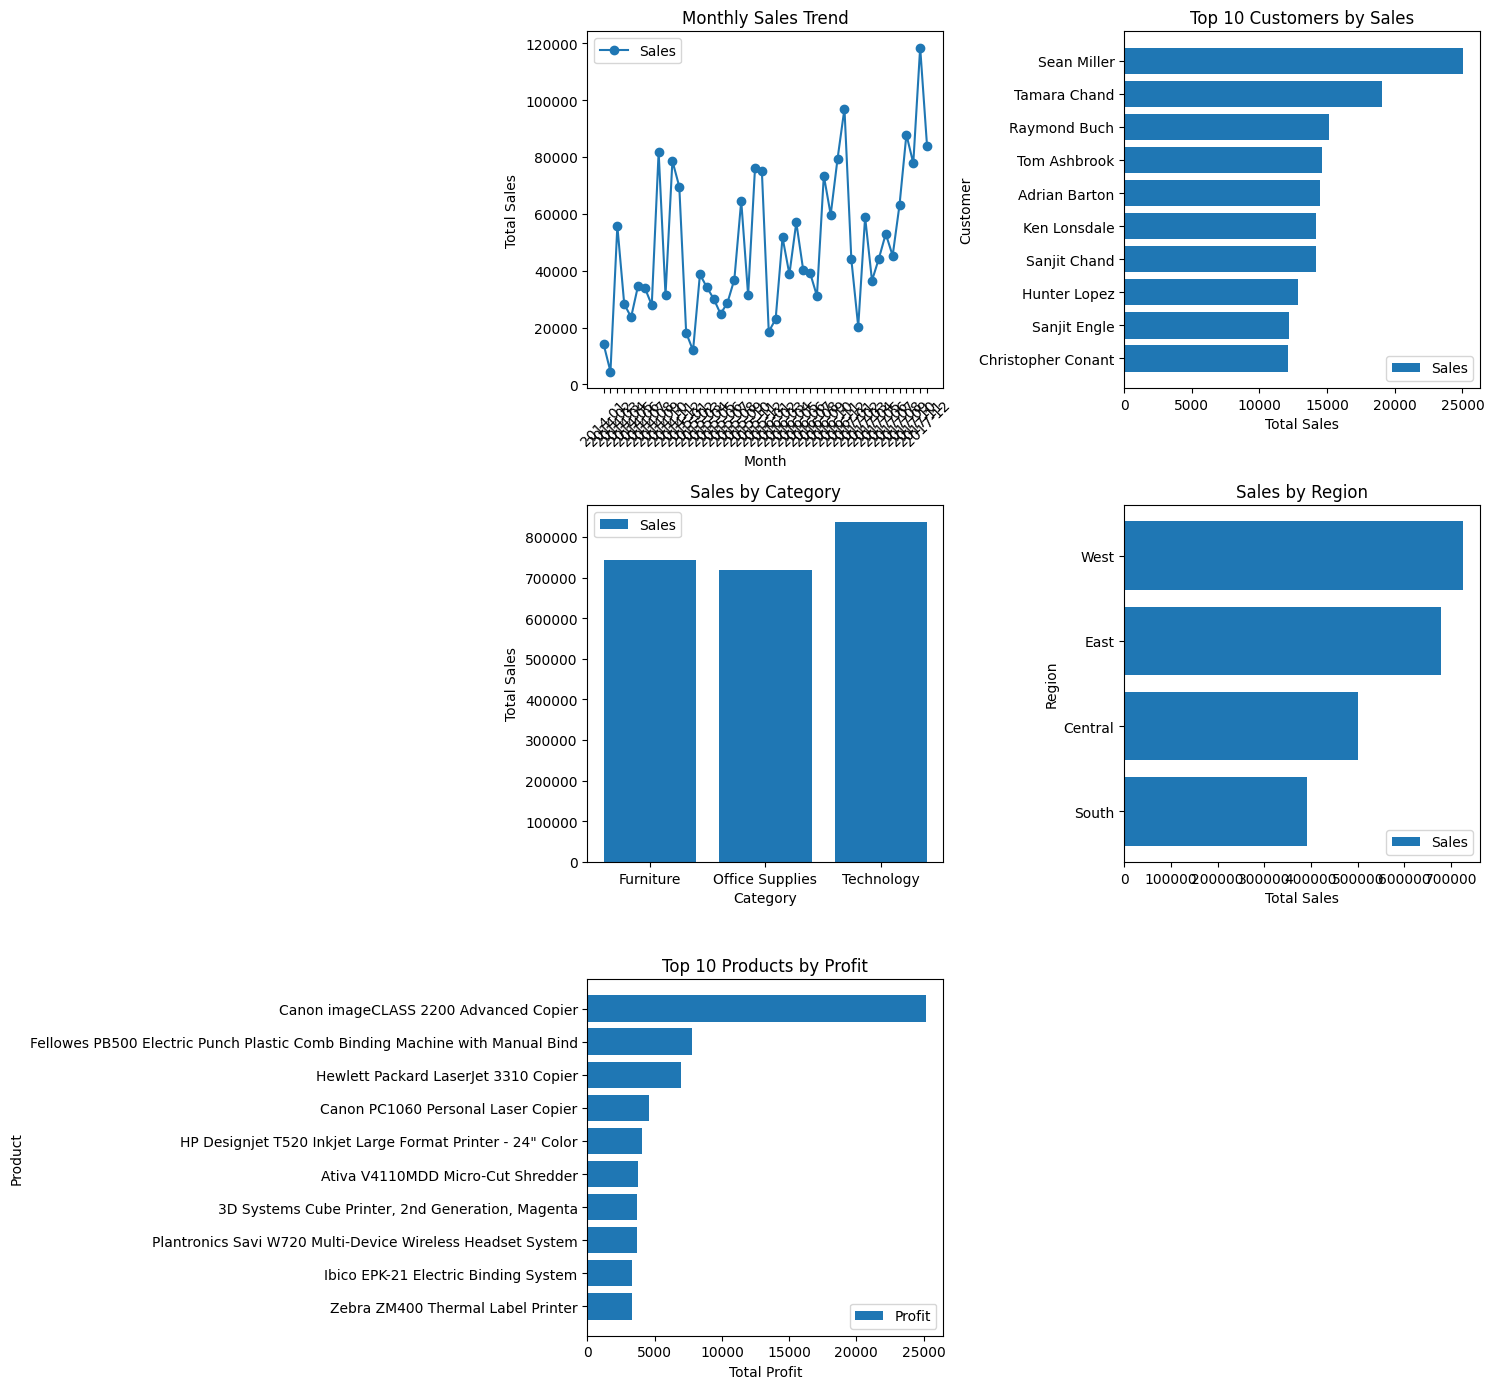

Dashboard and all 5 individual charts saved in outputs/


In [65]:

import pandas as pd
import matplotlib.pyplot as plt
import os

# 1. Load cleaned dataset
file_path = '/content/drive/MyDrive/Module-7_Introduction_to_Data_Science/mini_project/outputs/datasets/cleaned_customer_sales_analysis.csv'
output_folder = '/content/drive/MyDrive/Module-7_Introduction_to_Data_Science/mini_project/outputs/visuals'

df = pd.read_csv(file_path)
df['order_date'] = pd.to_datetime(df['order_date'], errors='coerce')
os.makedirs(output_folder, exist_ok=True)

# 2. Prepare data
monthly_sales = df.groupby(df['order_date'].dt.to_period('M'))['sales'].sum()
top_customers = df.groupby('customer_name')['sales'].sum().nlargest(10).sort_values()
category_sales = df.groupby('category')['sales'].sum()
region_sales = df.groupby('region')['sales'].sum().sort_values()
top_products = df.groupby('product_name')['profit'].sum().nlargest(10).sort_values()

# 3. Create 5 subplots
fig, axes = plt.subplots(3, 2, figsize=(15, 14))
axes = axes.flatten()

# Chart 1: Monthly Sales Trend
axes[0].plot(monthly_sales.index.astype(str), monthly_sales.values,
             marker='o', label='Sales')
axes[0].set_title('Monthly Sales Trend')
axes[0].set_xlabel('Month')
axes[0].set_ylabel('Total Sales')
axes[0].tick_params(axis='x', rotation=45)
axes[0].legend()

# Chart 2: Top 10 Customers
axes[1].barh(top_customers.index, top_customers.values, label='Sales')
axes[1].set_title('Top 10 Customers by Sales')
axes[1].set_xlabel('Total Sales')
axes[1].set_ylabel('Customer')
axes[1].legend()

# Chart 3: Sales by Category
axes[2].bar(category_sales.index, category_sales.values, label='Sales')
axes[2].set_title('Sales by Category')
axes[2].set_xlabel('Category')
axes[2].set_ylabel('Total Sales')
axes[2].legend()

# Chart 4: Sales by Region
axes[3].barh(region_sales.index, region_sales.values, label='Sales')
axes[3].set_title('Sales by Region')
axes[3].set_xlabel('Total Sales')
axes[3].set_ylabel('Region')
axes[3].legend()

# Chart 5: Top Products by Profit
axes[4].barh(top_products.index, top_products.values, label='Profit')
axes[4].set_title('Top 10 Products by Profit')
axes[4].set_xlabel('Total Profit')
axes[4].set_ylabel('Product')
axes[4].legend()

# Remove the unused sixth subplot
fig.delaxes(axes[5])

# 4. Format and save combined dashboard
plt.tight_layout()
plt.savefig(f'{output_folder}/sales_analysis_dashboard.png', dpi=300, bbox_inches='tight')
plt.show()

# 5. Save each chart separately
for i, name in enumerate([
    'monthly_sales_trend',
    'top_10_customers',
    'sales_by_category',
    'sales_by_region',
    'top_products_by_profit'
]):
    fig_single, ax = plt.subplots(figsize=(8, 5))
    source_axes = axes[i]

    # Copy chart data and labels into a standalone figure
    if i == 0:
        ax.plot(monthly_sales.index.astype(str), monthly_sales.values, marker='o', label='Sales')
        ax.tick_params(axis='x', rotation=45)
    elif i == 1:
        ax.barh(top_customers.index, top_customers.values, label='Sales')
    elif i == 2:
        ax.bar(category_sales.index, category_sales.values, label='Sales')
    elif i == 3:
        ax.barh(region_sales.index, region_sales.values, label='Sales')
    else:
        ax.barh(top_products.index, top_products.values, label='Profit')

    ax.set_title(source_axes.get_title())
    ax.set_xlabel(source_axes.get_xlabel())
    ax.set_ylabel(source_axes.get_ylabel())
    ax.legend()
    fig_single.tight_layout()
    fig_single.savefig(f'{output_folder}/{name}.png', dpi=300, bbox_inches='tight')
    plt.close(fig_single)

print("Dashboard and all 5 individual charts saved in outputs/")


# Task 10: Business Insights



## Insight 1: The West region is the strongest sales contributor

- Finding: The West region generates the highest sales and profit.
- Evidence: West sales were approximately 725,458, with profit of 108,418. South sales were approximately 391,722.
- Business Meaning: The West is an important revenue and profit contributor. Understanding what drives its performance could help the company improve results in other regions.

## Insight 2: High regional sales do not always mean strong profitability

- Finding: Central generates substantial sales but has relatively low profitability.
- Evidence: Central sales were approximately 501,240, with profit of 39,706—a profit margin of about 7.9%.
- Business Meaning: The region converts a relatively small share of sales into profit. Management should investigate whether product mix, discounts, or costs explain this gap.

## Insight 3: Sales are concentrated in a few states

- Finding: California and New York are major contributors to sales.
- Evidence: California generated approximately 457,688 in sales, while New York generated approximately 310,876.
- Business Meaning: These states are important markets to retain and develop. However, the company should also evaluate opportunities in lower-performing states to diversify growth.

## Insight 4: Sales fluctuate across months

- Finding: Monthly sales vary, indicating changes in demand over time.
- Evidence: November 2017 was the highest-sales month in your earlier analysis, with sales of approximately 118,448.
- Business Meaning: Understanding peak periods can improve inventory planning, staffing, and promotional timing. A single peak does not establish a recurring seasonal pattern, so comparisons across years are needed.

## Insight 5: Some months generate losses

- Finding: The business experiences periods when total profit becomes negative.
- Evidence: January 2015 recorded approximately −3,281 in profit, and July 2014 recorded approximately −841.
- Business Meaning: Some transactions or product combinations may be unprofitable during these periods. Investigating order-level profit, discounts, and product mix can help identify the source of losses.

## Insight 6: Revenue should be evaluated alongside customer and product profitability

- Finding: The highest-selling customers and products may not necessarily generate the highest profit.
- Evidence: Compare total sales and total profit in your customer and product analysis tables to identify high-sales, low-profit cases.
- Business Meaning: Focusing only on sales can lead to decisions that increase revenue without improving business performance. Profitability and customer value should also influence priorities.



Business Recommendations

# Recommendation 1: Improve profitability in low-margin regions

Focus first on the Central region, where the observed profit margin is approximately 7.9%, compared with 14.9% in the West.

Action: Review discount levels, product mix, and costs in Central. Set margin targets and monitor regional profit margins monthly.

# Recommendation 2: Use monthly trends to plan inventory and promotions

November 2017 had the highest monthly sales in the earlier analysis, at approximately 118,448.

Action: Compare monthly sales across years to identify recurring demand patterns. Adjust inventory, staffing, and promotional schedules to reduce stock shortages and unnecessary inventory.

# Recommendation 3: Prioritize profitable customers and products

The customer and product analyses allow the business to compare sales contribution with profit contribution.

Action: Identify high-sales, low-profit products and customers. Review pricing and discount policies, and target marketing toward customer segments that contribute strong profits—not just high revenue.


Task 11: Create GitHub Documentation (README.md and requirements.txt)

In [71]:
# Create README.md
import os

base = '/content/drive/MyDrive/Module-7_Introduction_to_Data_Science/mini_project/outputs'

readme_content = """# Customer Sales Analysis

## 1. Project Overview
This project analyzes Superstore sales data to understand sales performance,
profitability, customer purchasing behavior, and regional trends.

The goal is to identify business opportunities, improve profitability,
and support data-driven decision-making.

## 2. Dataset
The dataset is the Sample - Superstore dataset.
It contains order details, customers, products, sales, quantity, discount,
profit, shipping information, and geographical details.

## 3. Technologies Used
- Python
- Pandas
- NumPy
- SQL (SQLite)
- Matplotlib
- Seaborn
- Google Colab
- Git and GitHub

## 4. Project Structure
- data/: Original and cleaned datasets
- notebooks/: Python analysis notebooks
- sql/: SQL queries
- outputs/: Cleaned data and visualizations
- README.md: Project documentation
- requirements.txt: Required Python libraries

## 5. Analysis Performed
- Data cleaning and preprocessing
- Customer sales and profit analysis
- Product and category performance
- Regional and state-wise sales analysis
- Monthly and yearly sales trends
- SQL queries and statistical analysis
- Data visualization

## 6. Key Insights
- The West region generated the highest sales and profit.
- The South region had the lowest total sales among the four regions.
- California recorded the highest state-level sales.
- November 2017 had the highest monthly sales.
- Some months recorded negative profit, highlighting the need to
  investigate discounts, costs, and product performance.

## 7. How to Run
1. Clone or download this repository.
2. Install dependencies using: pip install -r requirements.txt
3. Open the notebook in Google Colab or Jupyter Notebook.
4. Update dataset paths if necessary.
5. Run the notebook cells in order.
6. Execute SQL queries from the sql folder using SQLite.

## Project Workflow
Python -> Data Cleaning -> SQL -> Analysis -> Visualization
-> Business Insights -> GitHub

## Final Deliverables
- Cleaned dataset
- Python notebook
- SQL queries
- Visualizations
- Business insights and recommendations
- Project documentation
"""

# Save README.md in the main project folder
with open(f'{base}/README.md', 'w', encoding='utf-8') as file:
    file.write(readme_content)

print("README.md created successfully!")
print("Saved at:", f'{base}/README.md')

README.md created successfully!
Saved at: /content/drive/MyDrive/Module-7_Introduction_to_Data_Science/mini_project/outputs/README.md


In [72]:
requirements = """pandas
numpy
matplotlib
seaborn
jupyter
"""

with open(f'{base}/requirements.txt', 'w', encoding='utf-8') as file:
    file.write(requirements)

print("requirements.txt created successfully!")

requirements.txt created successfully!


In [73]:
import os

print(os.listdir(base))

['datasets', 'sql', 'visuals', 'README.md', 'requirements.txt']
